<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet6%20(ANN)%20PBL/Praktikum%202%20(JS6)%20PBL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Langkah 1: Instalasi FAISS & Persiapan Dataset (cafes.csv & reviews.csv)

In [ ]:
# Jalankan di sel pertama (Google Colab / Jupyter)
!pip install faiss-cpu

import numpy as np
import pandas as pd
import faiss
import matplotlib.pyplot as plt
import time
from sklearn.preprocessing import StandardScaler, normalize

# Load 2 dataset
cafes = pd.read_csv('cafes.csv')
reviews = pd.read_csv('reviews.csv')

# Agregasi fitur dari reviews.csv berdasarkan cafe_id
reviews_agg = reviews.groupby('cafe_id').agg(
    avg_review_rating=('rating', 'mean'),
    total_likes=('likes', 'sum'),
    avg_text_len=('text', lambda x: x.astype(str).str.len().mean())
).reset_index()

# Gabungkan kedua dataset
merged = pd.merge(cafes, reviews_agg, on='cafe_id', how='left').fillna(0)
print(f"Dataset siap digunakan! Total data cafe: {len(merged)} baris")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.5/19.5 MB 48.5 MB/s  0:00:00
Dataset siap digunakan! Total data cafe: 99 baris


#Langkah 2: Percobaan Dasar FAISS 2D (IndexFlatL2 vs IndexIVFPQ)

Query Cafe: ARTE COFFEE & EATERY

--- Hasil Pencarian 2D (Euclidean / L2) ---
Exact NN (Flat) indices: [ 0 11 31] | distances: [0. 0. 0.]
Nama Cafe (Exact): ['ARTE COFFEE & EATERY', 'ARTE COFFEE & EATERY', 'ARTE COFFEE & EATERY']
Waktu Exact: 0.2112 ms

IVF+PQ indices: [ 0 11 31] | distances: [2.4880137e-08 2.4880137e-08 2.4880137e-08]
Nama Cafe (IVF+PQ): ['ARTE COFFEE & EATERY', 'ARTE COFFEE & EATERY', 'ARTE COFFEE & EATERY']
Waktu IVF+PQ: 0.2398 ms


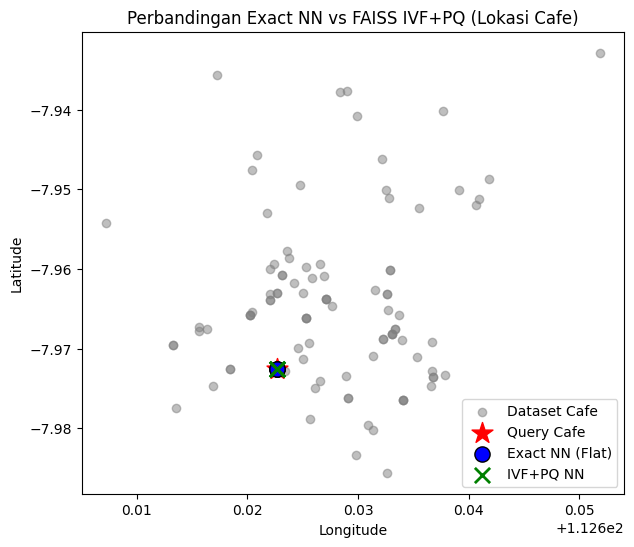

In [ ]:
# 1. Siapkan dataset 2D (Latitude & Longitude) dalam format float32 (wajib untuk FAISS)
X_2d = merged[['latitude', 'longitude']].values.astype('float32')

# Ambil cafe indeks ke-0 (ARTE COFFEE & EATERY) sebagai titik query
query_idx = 0
query_2d = X_2d[query_idx].reshape(1, -1)
print(f"Query Cafe: {merged.loc[query_idx, 'name']}")

# 2. Exact NN dengan IndexFlatL2 (Brute Force)
d = 2  # dimensi = 2
index_flat = faiss.IndexFlatL2(d)
index_flat.add(X_2d)

start = time.time()
D_flat, I_flat = index_flat.search(query_2d, 3)  # Cari 3 cafe terdekat
time_flat = time.time() - start

# 3. IVF + PQ (Approximate NN)
nlist = 5   # Jumlah cluster (inverted list)
m = 2       # Jumlah subvector (harus membagi habis dimensi d=2)
nbits = 4   # 4 bit per subvector (2^4 = 16 centroids, cocok untuk 99 data)

quantizer = faiss.IndexFlatL2(d)
index_ivfpq = faiss.IndexIVFPQ(quantizer, d, nlist, m, nbits)
index_ivfpq.train(X_2d)  # Training centroid pada data cafe
index_ivfpq.add(X_2d)

start = time.time()
D_ivfpq, I_ivfpq = index_ivfpq.search(query_2d, 3)
time_ivfpq = time.time() - start

# 4. Print Hasil
print("\n--- Hasil Pencarian 2D (Euclidean / L2) ---")
print("Exact NN (Flat) indices:", I_flat[0], "| distances:", D_flat[0])
print("Nama Cafe (Exact):", merged.loc[I_flat[0], 'name'].tolist())
print(f"Waktu Exact: {time_flat*1000:.4f} ms")

print("\nIVF+PQ indices:", I_ivfpq[0], "| distances:", D_ivfpq[0])
print("Nama Cafe (IVF+PQ):", merged.loc[I_ivfpq[0], 'name'].tolist())
print(f"Waktu IVF+PQ: {time_ivfpq*1000:.4f} ms")

# 5. Visualisasi
plt.figure(figsize=(7, 6))
plt.scatter(X_2d[:, 1], X_2d[:, 0], alpha=0.5, c='gray', label="Dataset Cafe")
plt.scatter(query_2d[:, 1], query_2d[:, 0], c='red', marker='*', s=250, label="Query Cafe")
plt.scatter(X_2d[I_flat[0], 1], X_2d[I_flat[0], 0], c='blue', s=120, edgecolor='k', label="Exact NN (Flat)")
plt.scatter(X_2d[I_ivfpq[0], 1], X_2d[I_ivfpq[0], 0], c='green', marker='x', s=120, linewidths=2, label="IVF+PQ NN")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.title("Perbandingan Exact NN vs FAISS IVF+PQ (Lokasi Cafe)")
plt.show()

#Langkah 3: Percobaan Lanjutan (Metric Distance Berbeda & 2D vs 5D Data)

In [ ]:
# Siapkan 5 fitur gabungan dari cafes.csv dan reviews.csv
fitur_5d = ['latitude', 'longitude', 'rating', 'review_count', 'avg_review_rating']
scaler = StandardScaler()
X_5d = scaler.fit_transform(merged[fitur_5d]).astype('float32')

def uji_faiss(data, metric_type="L2", nama_percobaan=""):
    d = data.shape[1]
    query = data[0].reshape(1, -1)

    # Jika menggunakan Inner Product (Cosine Similarity), vektor perlu dinormalisasi L2
    if metric_type == "IP":
        data_proc = normalize(data, norm='l2').astype('float32')
        query_proc = normalize(query, norm='l2').astype('float32')
        index_exact = faiss.IndexFlatIP(d)
        quantizer = faiss.IndexFlatIP(d)
        metric_faiss = faiss.METRIC_INNER_PRODUCT
    else:
        data_proc = data
        query_proc = query
        index_exact = faiss.IndexFlatL2(d)
        quantizer = faiss.IndexFlatL2(d)
        metric_faiss = faiss.METRIC_L2

    # 1. Exact Search
    index_exact.add(data_proc)
    t0 = time.time()
    _, idx_exact = index_exact.search(query_proc, 3)
    t_exact = (time.time() - t0) * 1000

    # 2. IVF+PQ Search (m=1 agar selalu membagi habis dimensi ganjil seperti 5D)
    index_approx = faiss.IndexIVFPQ(quantizer, d, 5, 1, 4, metric_faiss)
    index_approx.train(data_proc)
    index_approx.add(data_proc)
    t0 = time.time()
    _, idx_approx = index_approx.search(query_proc, 3)
    t_approx = (time.time() - t0) * 1000

    print(f"=== {nama_percobaan} ===")
    print(f"Metric       : {metric_type}")
    print(f"Dimensi      : {d}D ({len(data)} data)")
    print(f"Index Exact  : {idx_exact[0]} | Index IVF+PQ: {idx_approx[0]}")
    print(f"Waktu Exact  : {t_exact:.4f} ms | Waktu IVF+PQ: {t_approx:.4f} ms\n")

# Jalankan 4 variasi eksperimen pada dataset Cafe & Review
X_2d_scaled = scaler.fit_transform(merged[['latitude', 'longitude']]).astype('float32')

uji_faiss(X_2d_scaled, metric_type="L2", nama_percobaan="Percobaan A (2D - Euclidean)")
uji_faiss(X_2d_scaled, metric_type="IP", nama_percobaan="Percobaan B (2D - Inner Product / Cosine)")
uji_faiss(X_5d, metric_type="L2", nama_percobaan="Percobaan C (5D - Euclidean)")
uji_faiss(X_5d, metric_type="IP", nama_percobaan="Percobaan D (5D - Inner Product / Cosine)")

=== Percobaan A (2D - Euclidean) ===
Metric       : L2
Dimensi      : 2D (99 data)
Index Exact  : [ 0 11 31] | Index IVF+PQ: [ 0 11 31]
Waktu Exact  : 0.0391 ms | Waktu IVF+PQ: 0.0548 ms

=== Percobaan B (2D - Inner Product / Cosine) ===
Metric       : IP
Dimensi      : 2D (99 data)
Index Exact  : [31 11  0] | Index IVF+PQ: [49 17 11]
Waktu Exact  : 0.0277 ms | Waktu IVF+PQ: 0.0396 ms

=== Percobaan C (5D - Euclidean) ===
Metric       : L2
Dimensi      : 5D (99 data)
Index Exact  : [ 0 11 31] | Index IVF+PQ: [ 0  8 11]
Waktu Exact  : 0.0312 ms | Waktu IVF+PQ: 0.0336 ms

=== Percobaan D (5D - Inner Product / Cosine) ===
Metric       : IP
Dimensi      : 5D (99 data)
Index Exact  : [11  0 54] | Index IVF+PQ: [31 11  0]
Waktu Exact  : 0.0253 ms | Waktu IVF+PQ: 0.0324 ms



| Distance Metrics | Dimensi | Jumlah Data | Hasil Index (Exact vs IVF+PQ) | Waktu Komputasi (ms) |
| :--- | :---: | :---: | :--- | :--- |
| Euclidean (L2) | 2D | 99 | [0 11 31] vs [0 11 31] | 0.0391 vs 0.0548 |
| Inner Product (Cosine) | 2D | 99 | [31 11 0] vs [49 17 11] | 0.0277 vs 0.0396 |
| Euclidean (L2) | 5D | 99 | [0 11 31] vs [0 8 11] | 0.0312 vs 0.0336 |
| Inner Product (Cosine) | 5D | 99 | [11 0 54] vs [31 11 0] | 0.0253 vs 0.0324 |